In [1]:
using Korg
using CSV
using DataFrames
using PyPlot
using PyCall
using Statistics
using StatsBase
using Distributed
using Pkg
using Polynomials
fits = pyimport("astropy.io.fits")
plt = pyimport("matplotlib.pyplot")
pyimport("matplotlib.pyplot").ion()
ast = pyimport("ast")
np = pyimport("numpy")

gammaincc = pyimport("scipy.special").gammaincc

# models = pyimport("astropy").modeling.models
#  astropy.modeling import models, fitting

PyObject <ufunc 'gammaincc'>

In [5]:
x = 0.01:0.01:0.99
y = (x.^2).*5 - x.*2 .+ 6
fit(x, y, 10)

UndefVarError: UndefVarError: `fit` not defined in `Main`
Hint: It looks like two or more modules export different bindings with this name, resulting in ambiguity. Try explicitly importing it from a particular module, or qualifying the name with the module it should come from.
Hint: a global variable of this name also exists in Polynomials.
Hint: a global variable of this name also exists in StatsBase.

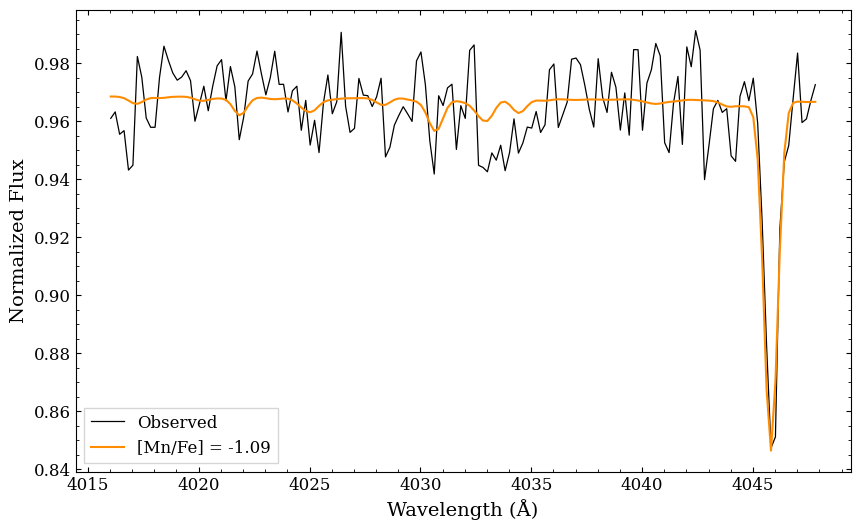

In [33]:
# Loading in the test data
data_path = "/data/misfit/benlowe/xshooter/korg_data/synths/ra_1633-2814_s284/Mn_I/obs/line_4033.06/spectra/-1.29_spec.csv"
# data_path = "/data/misfit/benlowe/xshooter/korg_data/synths/ra_1633-2814_s284/Eu_II/obs/line_4129.725/spectra/0.44_spec.csv"
data = CSV.read(data_path, DataFrame)

obs_wave = ast.literal_eval(data.obs_wave[1])
obs_flux = ast.literal_eval(data.obs_flux[1])
obs_flux_err = ast.literal_eval(data.obs_flux_err[1])

fits_wave = ast.literal_eval(data.fit_wave[1])
fits_flux = ast.literal_eval(data.fit_flux[1])

figure(figsize=(10, 6))
plot(obs_wave, obs_flux, label="Observed", color="black", linewidth=0.9)
plot(fits_wave, fits_flux, label="[Mn/Fe] = -1.09", color="darkorange")
xlabel("Wavelength (Å)")
ylabel("Normalized Flux")
legend(fancybox=false)
display(gcf())

## Determining upper-limits procedure

To determine upper-limits, we'll use the following procedure:
1. Calculate the minimum detectable EW using Eqn. 6' from Cayrel (1988) $$EW_{\rm min} = 2.3 \sqrt{w . \delta x} \epsilon$$ whereby $$\frac{1}{\epsilon} = S/N$$ $$\delta x = \textrm{pixel step}$$ $$w = \textrm{instrumental resolution}$$ 
2. Calculate a Gaussian that is rescaled to the correct EW with a FWHM according to the instrumental resolving power. The Gaussian equation is $$G(\lambda) = 1 - A \times exp(-\frac{(\lambda - \lambda_{0})^2}{2 \sigma^2}),$$ whereby $A$ can be identified from the EW via $$A = \frac{EW}{\sigma \sqrt{2 \pi}},$$ $\sigma$ identified from the FWHM $$\sigma = \frac{\rm FWHM}{2 \sqrt{2 ln 2}},$$ with the FWHM found from the spectra's resolving power $$\rm{FWHM} = \frac{\lambda}{R},$$ with $\lambda$ being the central wavelength of the line.
3. Fit Korg to this (using the observed flux errors) to measure the abundance. If the observed fit is smaller than this, then there's no detection, and we use the minimum abundance as the upper-limit


#### Step 1: calcualate minimum EW

In [36]:
function ew_min(wave_cent, sn, pixel_step, res)
    """ Calculate the minimum equivalent width (EW) for a given signal-to-noise ratio (sn), pixel step, and resolution (res).

    Parameters:
    ----------
    sn : float
        The signal-to-noise ratio of the spectra.
    pixel_step : float
        The pixel step size in the spectra.
    res : float
        The resolution of the spectra.
    
    Returns:
    -------
    min_ew : float
        The minimum observed equivalent width of the given spectra.
    """

    # Defining the parameters
    epsilon = 1/sn
    delta_x = pixel_step
    fwhm = wave_cent / res
    
    # Calculate the minimum equivalent width (in Angstroms)
    min_ew = 3 * (1.5 * sqrt(fwhm * delta_x) * epsilon)
    return min_ew
end

# Calculate the minimum equivalent width for the observed spectrum
sn = 122.4875760981559
pixel_step = mean(diff(obs_wave))
res = 5400
wave_cent = 4033.06 
# wave_cent = 4129.725

min_ew = ew_min(wave_cent, sn, pixel_step, res)
println("Minimum Equivalent Width: $(round(min_ew, digits=4)) Å")

Minimum Equivalent Width: 0.0142 Å


#### Step 2: Calculate the Gaussian

In [147]:
function gauss(waves, wave_cent, res, ew)
    """ Creates a Gaussian function rescaled to the minimum EW, with a FWHM determined by the spectral resolution.
    
    Parameters:
    ----------
    waves : Vector{Float64}
        The wavelength array for which the Gaussian is calculated.
    wave_cent : Float64
        The central wavelength of the line.
    res : Float64
        The spectral resolution of the instrument.
    ew : Float64
        The equivalent width of the line.

    Returns:
    -------
    gaussian : Vector{Float64}
        The Gaussian function values at the specified wavelengths.
    """

    # Calculate the FWHM given the spectral resolution
    fwhm = wave_cent / res
    println(fwhm)

    # Calculate the standard deviation of the Gaussian using the FWHM
    sigma = fwhm / (2 * sqrt(2 * log(2) * 2))
    println(sigma)

    # Calculate the amplitude
    A = ew / (sigma * sqrt(2 * pi))
    println(A)

    # Create the Gaussian function
    gaussian = 1 .- A * exp.(-1 * (waves .- wave_cent).^2 ./ (2 * sigma^2))

    return gaussian
end

spec_theoretic = gauss(obs_wave, wave_cent, res, min_ew)

# figure(figsize=(10, 6))
# plot(obs_wave, spec_theoretic, label="Theoretical", color="black", linewidth=0.9)
# plot(obs_wave, obs_flux, label="Observed", color="darkgreen", linewidth=0.9)
# xlabel("Wavelength (Å)")
# ylabel("Normalized Flux")
# legend(fancybox=false)
# display(gcf())
# savefig("/data/misfit/benlowe/results/upper_limits/theoretical_spec.png", dpi=300, transparent=false, facecolor="white")

160-element Vector{Float64}:
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 ⋮
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0
 1.0

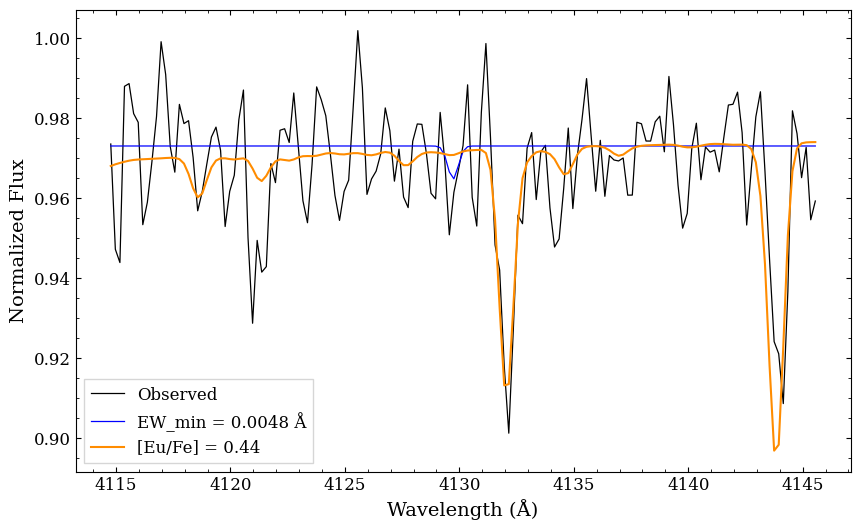

In [59]:
figure(figsize=(10, 6))
plot(obs_wave, obs_flux, label="Observed", color="black", linewidth=0.9)
plot(obs_wave, spec_theoretic, color="blue", linewidth=0.9, label="EW_min = $(round(min_ew, digits=4)) Å")
plot(fits_wave, fits_flux, label="[Eu/Fe] = 0.44", color="darkorange")
xlabel("Wavelength (Å)")
ylabel("Normalized Flux")
legend(fancybox=false)
display(gcf())

#### Step 3: fit the theoretical spectra by Korg

In [127]:
function get_window(path)
    """
    Loading in the window from the given path.

    Parameters
    ----------
    path : Str
        Path to the window.

    Returns
    -------
    windows : Dict
        Dictionary with the windows for each element.
    """

    # Loading in the window from the given path
    windowtable = CSV.read(path, DataFrame)

    # Creating a dictionary with the windows
    windows = Dict()
    for row in eachrow(windowtable)
        # atomic number
        Z = Korg.get_atoms(Korg.Species(row.species))[1]
        # get the windows for this element so far 
        wins = get(windows, Z, [])
        # add the new window
        push!(wins, (row.wavepeak, Korg.air_to_vacuum(row.wavebase), Korg.air_to_vacuum(row.wavetop)))
        # update the dictionary
        windows[Z] = wins
    end

    return windows
end

function get_linelist(path)
    """
    Retrieves the line list from the given path, then converts to format accepted by Korg.

    Parameters
    ----------
    path : Str
        Path to the linelist.

    Returns
    -------
    linelist : Vector
        The linelist in a suitable format for Korg.
    """

    # Loading in the linelist from the given path
    linetable = CSV.read(path, DataFrame)
    linetable = sort(linetable, :wave)

    # Extracting
    linelist = Korg.Line.(Korg.air_to_vacuum.(linetable.wave),
                          linetable.loggf,
                          Korg.Species.(linetable.species),
                          linetable.elow) 

    return linelist 
end

function linelist_trim(linelist, element)
    """ Trims the linelist to only include lines for a specific element.

    Parameters
    ----------
    linelist : Vector{Korg.Line}
        The original linelist to be trimmed.
    element : String
        The element for which the linelist should be trimmed.

    Returns
    -------
    linelist_trim : Vector{Korg.Line}
        The trimmed linelist containing only lines for the specified element.
    """
    trimmed_linelist = []
    for i in 1:length(linelist)

        # Extracting the species name
        species = string(vald_linelist[i].species)

        if species == element

            # Extracting the relevant information
            wave = float(vald_linelist[i].wl * 10e7) # Convert to Angstroms
            log_gf = float(vald_linelist[i].log_gf)
            E_lower = float(vald_linelist[i].E_lower)
            
            # Saving into dictionary
            line_dict = Dict("species" => species, "wave" => wave, "log_gf" => log_gf, "E_lower" => E_lower)
            push!(trimmed_linelist, line_dict)
        end
    end

    # Converting to DataFrame
    trimmed_df = DataFrame(trimmed_linelist)

    # Converting into Korg.Line format
    linelist_trim = Korg.Line.(trimmed_df.wave,
                               trimmed_df.log_gf,
                               Korg.Species.(trimmed_df.species),
                               trimmed_df.E_lower)
    return linelist_trim
end

linelist = get_linelist("/data/misfit/benlowe/xshooter/linelist/abund_lines/v3/Mn_I/lines_Mn_I.csv")

# ---INPUTS--- #
star_paths = sort(filter(isdir, readdir("/data/misfit/benlowe/xshooter/reduced_data/comb_spec", join=true)))
star_paths = [star for star in star_paths if split(star, "/")[end] == "ra_1633-2814_s284"]

# Stellar parameters
emp_params = CSV.read("/data/misfit/benlowe/xshooter/korg_data/abunds/final/stellar_params.csv", DataFrame)
emp_params = emp_params[emp_params.star_id .== "ra_1633-2814_s284", :]

# Loading in the windows for the elements
elements = "Mn I"
windows_path = "/data/misfit/benlowe/xshooter/linelist/abund_lines/v3/"
el_windows_path = windows_path * "$(split(elements, " ")[1])_$(split(elements, " ")[2])/windows_$(split(elements, " ")[1])_$(split(elements, " ")[2]).csv"
windows = get_window(el_windows_path)
el_windows = windows[Korg.atomic_numbers["Mn"]]

# Loading in the linelist for the element
el_linelist_path = "/data/misfit/benlowe/xshooter/linelist/abund_lines/v3/$(split(elements, " ")[1])_$(split(elements, " ")[2])/"
mask_lines = false # Used to mask lines in the windows. Need separate file for this.
vald_linelist = Korg.read_linelist("/data/misfit/benlowe/xshooter/linelist/vald_3300-9000_linelist_metal-poor.lin", format="vald", isotopic_abundances=Korg.isotopic_abundances)

# Trimming the linelist to only include lines for the element
vald_linelist_trim = linelist_trim(vald_linelist, "Mn I")


# ---RUNNING KORG--- #
# Defining the fixed parameters
params = (Teff = emp_params.teff[1], logg = emp_params.logg[1], m_H = emp_params.Fe_it2[1], vmic = emp_params.vmic[1], vsini = emp_params.vsini[1], epsilon = 0)
guesses = Dict("Mn" => 0)

# Defining the data for the given line
wave = Korg.air_to_vacuum.(obs_wave)
wavemin = Korg.air_to_vacuum.(obs_wave[1])
wavemax = Korg.air_to_vacuum.(obs_wave[end])
flux = spec_theoretic
flux_err = obs_flux_err
res = res


# Getting the window properties
line_peak = el_windows[1][1]
windmin = el_windows[1][2]
windmax = el_windows[1][3]

# Fitting the spectrum
println("Fitting the spectra")
@time spec_fit = Korg.Fit.fit_spectrum(wave, flux, flux_err, vald_linelist, guesses, params, R=res,
windows=[(windmin, windmax)], adjust_continuum=false, precision=1e-6)

# Extracting the results
best_fit = spec_fit.best_fit_flux
fit_mask = spec_fit.obs_wl_mask
trace = spec_fit.trace

# Converting to air, then getting the central wavelength
wave_air = Korg.vacuum_to_air.(wave)
windmin = Korg.vacuum_to_air(windmin)
windmax = Korg.vacuum_to_air(windmax)

obs_spec_wind = 5 # A
spec_mask = (wave_air .> windmin-obs_spec_wind) .& (wave_air .< windmax+obs_spec_wind)

# Getting the abundances
el_xh_abund = spec_fit.best_fit_params["Mn"] # in [X/H]
el_xfe_abund = el_xh_abund - params.m_H # in [X/Fe]



-1.5494771311511388

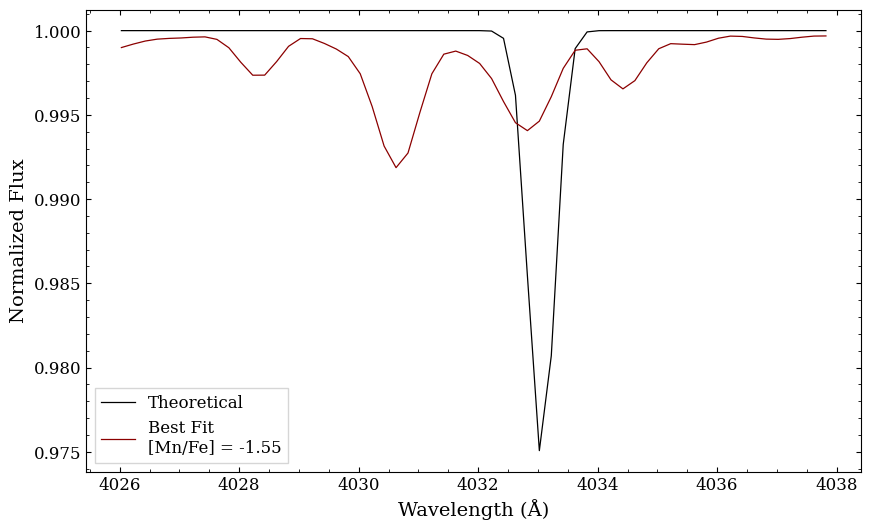

In [149]:
figure(figsize=(10, 6))
plot(wave_air[fit_mask], spec_theoretic[fit_mask], label="Theoretical", color="black", linewidth=0.9)
plot(wave_air[fit_mask], best_fit, label="Best Fit\n[Mn/Fe] = $(round(el_xfe_abund, digits=2))", color="darkred", linewidth=0.9)
legend(fancybox=false)
xlabel("Wavelength (Å)")
ylabel("Normalized Flux")
display(gcf())
savefig("/data/misfit/benlowe/results/upper_limits/theoretical_spec_fit.png", dpi=300, transparent=false, facecolor="white")

In [ ]:
function linelist_trim(linelist, element)
    """ Trims the linelist to only include lines for a specific element.

    Parameters
    ----------
    linelist : Vector{Korg.Line}
        The original linelist to be trimmed.
    element : String
        The element for which the linelist should be trimmed.

    Returns
    -------
    linelist_trim : Vector{Korg.Line}
        The trimmed linelist containing only lines for the specified element.
    """
    trimmed_linelist = []
    for i in 1:length(linelist)

        # Extracting the species name
        species = string(vald_linelist[i].species)

        if species == element

            # Extracting the relevant information
            wave = float(vald_linelist[i].wl * 10e7) # Convert to Angstroms
            log_gf = float(vald_linelist[i].log_gf)
            E_lower = float(vald_linelist[i].E_lower)
            
            # Saving into dictionary
            line_dict = Dict("species" => species, "wave" => wave, "log_gf" => log_gf, "E_lower" => E_lower)
            push!(trimmed_linelist, line_dict)
        end
    end

    # Converting to DataFrame
    trimmed_df = DataFrame(trimmed_linelist)

    # Converting into Korg.Line format
    linelist_trim = Korg.Line.(trimmed_df.wave,
                               trimmed_df.log_gf,
                               Korg.Species.(trimmed_df.species),
                               trimmed_df.E_lower)
    return linelist_trim
end

vald_linelist_trim = linelist_trim(vald_linelist, "Mn I")

3048-element Vector{Korg.Line{Float64, Float64, Float64, Float64, Float64, Float64}}:
 Mn I 3300.05619 Å (log gf = -3.47, χ = 2.16 eV)
 Mn I 3300.06204 Å (log gf = -3.3, χ = 2.16 eV)
 Mn I 3300.06402 Å (log gf = -2.69, χ = 2.16 eV)
 Mn I 3300.06698 Å (log gf = -3.3, χ = 2.16 eV)
 Mn I 3300.06839 Å (log gf = -2.95, χ = 2.16 eV)
 Mn I 3300.07107 Å (log gf = -3.4, χ = 2.16 eV)
 Mn I 3300.0718 Å (log gf = -3.28, χ = 2.16 eV)
 Mn I 3300.07431 Å (log gf = -3.73, χ = 2.16 eV)
 Mn I 3300.07432 Å (log gf = -3.66, χ = 2.16 eV)
 Mn I 3300.07595 Å (log gf = -4.43, χ = 2.16 eV)
 ⋮
 Mn I 8743.31643 Å (log gf = -2.92, χ = 4.43 eV)
 Mn I 8743.3682 Å (log gf = -1.62, χ = 4.43 eV)
 Mn I 8743.40961 Å (log gf = -1.08, χ = 4.43 eV)
 Mn I 8743.41582 Å (log gf = -2.82, χ = 4.43 eV)
 Mn I 8743.45723 Å (log gf = -1.67, χ = 4.43 eV)
 Mn I 8743.48829 Å (log gf = -1.21, χ = 4.43 eV)
 Mn I 8743.49301 Å (log gf = -2.96, χ = 4.43 eV)
 Mn I 8743.52407 Å (log gf = -1.86, χ = 4.43 eV)
 Mn I 8743.54477 Å (log gf = -1.35

In [108]:
vald_linelist_trim

0×0 DataFrame

In [117]:
trimmed_linelist = []
for i in 1:length(vald_linelist)

    # Extracting the species name
    species = string(vald_linelist[i].species)

    if species == "Mn I"

        # Extracting the relevant information
        wave = float(vald_linelist[i].wl * 10e7) # Convert to Angstroms
        log_gf = float(vald_linelist[i].log_gf)
        E_lower = float(vald_linelist[i].E_lower)
        
        line_dict = Dict("species" => species, "wave" => wave, "log_gf" => log_gf, "E_lower" => E_lower)
        push!(trimmed_linelist, line_dict)
    end
end

# trimmed_df = DataFrame(trimmed_linelist)


# vald_linelist[1].species
# vald_linelist[1].wl * 10e7
# vald_linelist[1].log_gf
# vald_linelist[1].E_lower

In [118]:
trimmed_linelist

3048-element Vector{Any}:
 Dict{String, Any}("E_lower" => 2.1637, "log_gf" => -3.466, "wave" => 3300.0561900000002, "species" => "Mn I")
 Dict{String, Any}("E_lower" => 2.1637, "log_gf" => -3.303, "wave" => 3300.06204, "species" => "Mn I")
 Dict{String, Any}("E_lower" => 2.1637, "log_gf" => -2.688, "wave" => 3300.06402, "species" => "Mn I")
 Dict{String, Any}("E_lower" => 2.1637, "log_gf" => -3.298, "wave" => 3300.06698, "species" => "Mn I")
 Dict{String, Any}("E_lower" => 2.1637, "log_gf" => -2.951, "wave" => 3300.0683900000004, "species" => "Mn I")
 Dict{String, Any}("E_lower" => 2.1637, "log_gf" => -3.4, "wave" => 3300.07107, "species" => "Mn I")
 Dict{String, Any}("E_lower" => 2.1637, "log_gf" => -3.282, "wave" => 3300.0718, "species" => "Mn I")
 Dict{String, Any}("E_lower" => 2.1637, "log_gf" => -3.729, "wave" => 3300.07431, "species" => "Mn I")
 Dict{String, Any}("E_lower" => 2.1637, "log_gf" => -3.662, "wave" => 3300.0743200000006, "species" => "Mn I")
 Dict{String, Any}("E_lowe

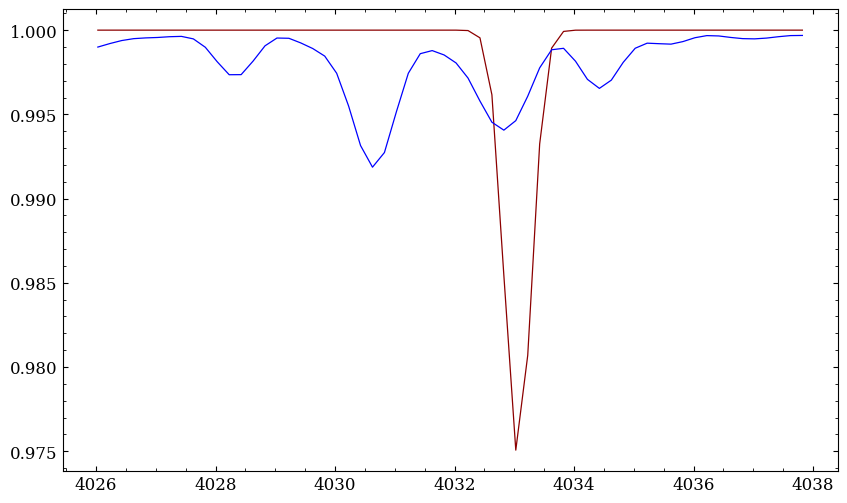

#### Trying a new approach: convert from EW to [X/Fe] using the new Korg function Korg.Fit.ews_to_abundance

In [52]:
# Loading in the stellar parameters
emp_params = CSV.read("/data/misfit/benlowe/xshooter/korg_data/abunds/final/stellar_params.csv", DataFrame)
emp_params = emp_params[emp_params.star_id .== "ra_1633-2814_s284", :]

teff = emp_params.teff[1] # in K
logg = emp_params.logg[1] # in log(cm/s^2)
feh = emp_params.Fe_it2[1] # in [Fe/H]
ah = 0.4 + feh # in [A/H]

# Loading in the linelist
# linelist = get_linelist("/data/misfit/benlowe/xshooter/linelist/abund_lines/v3/Mn_I/lines_Mn_I.csv")
linelist = get_linelist("/data/misfit/benlowe/xshooter/linelist/abund_lines/v3/Eu_II/lines_Eu_II.csv")


# Loading in the chemical abundances
emp_abunds = CSV.read("/data/misfit/benlowe/xshooter/korg_data/abunds/final/stellar_abunds.csv", DataFrame)
emp_abunds = emp_abunds[emp_abunds.star_id .== "ra_1633-2814_s284", :]

A_x = Korg.format_A_X(feh, ah, Dict("Fe" => feh, "Mg" => emp_abunds.Mg_I_xh_it2[1], "Ca" => emp_abunds.Ca_II_xh_it2[1],
"Ba" => emp_abunds.Ba_II_xh_it2[1], "Al" => emp_abunds.Al_I_xh_it2[1], "Mn" => emp_abunds.Mn_I_xh_it2[1],
"Cr" => emp_abunds.Cr_I_xh_it2[1], "Co" => emp_abunds.Co_I_xh_it2[1], "Ni" => emp_abunds.Ni_I_xh_it2[1],
"Na" => emp_abunds.Na_I_xh_it2[1], "Eu" => emp_abunds.Eu_II_xh_it2[1], "Si" => emp_abunds.Si_I_xh_it2[1],
"Ti" => emp_abunds.Ti_II_xh_it2[1], "Sc" => emp_abunds.Sc_II_xh_it2[1], "Sr" => emp_abunds.Sr_II_xh_it2[1],
"N" => emp_abunds.N_I_xh_it2[1], "C" => emp_abunds.C_I_xh_it2[1]))

# Interpolating the MARCS model atmosphere
atm = Korg.interpolate_marcs(teff, logg, A_x)

# Loading in the solar abundances from Asplund et al. (2021)
solar_abunds_ax = Korg.asplund_2020_solar_abundances

@time min_abund = Korg.Fit.ews_to_abundances(atm, linelist, A_x, [min_ew * 1000])
min_abund_xfe = min_abund[1] - solar_abunds_ax[Korg.atomic_numbers["Eu"]] - feh
# min_abund_xfe = min_abund[1] - solar_abunds_ax[Korg.atomic_numbers["Mn"]] - feh

println("Mimimum observed abundance: [Mn/Fe] = $(round(min_abund_xfe, digits=2))")

  0.436618 seconds (2.09 M allocations: 165.176 MiB, 7.46% gc time)
Mimimum observed abundance: [Mn/Fe] = 1.12


## Determining upper-limits by using the reduced chisquared

To determine upper-limits, we'll try the following procedure:
1. Calculate the reduced chisquared between the observed with the best fittig spectra.
2. Calculate the reduced chisquared between the observed and an ``empty" spectrum (straight line).
3. Compare: if the first reduced chisquared is smaller than the second, then it's a detection. If the two are similar, then you can't separate the two, and thus is an upper-limit.

In [2]:
function reduced_chisqr(obs_flux, obs_flux_err, fit_flux, n_params)
    """ Calculate the chi-squared and reduced chi-squared for the given observed and the fitted flux.

    Parameters
    ----------
    obs_flux : Vector{Float64}
        The observed flux values.
    obs_flux_err : Vector{Float64}
        The errors in the observed flux values.
    fit_flux : Vector{Float64}
        The fitted flux values.
    n_params : Int
        The number of parameters in the fit.

    Returns
    -------
    chisq : Float64
        The chi-squared value.
    reduced_chisq : Float64
        The reduced chi-squared value.
    """
    # Calculate chi-squared
    chisq = sum(((obs_flux .- fit_flux) .^ 2) ./ (obs_flux_err .^ 2))

    # Degrees of freedom
    dof = length(obs_flux) - n_params

    # Reduced chi-squared
    reduced_chisq = chisq / dof

    return chisq, reduced_chisq
end

reduced_chisqr (generic function with 1 method)

### Star ra_1633-2814_s284

#### For Mn

In [3]:
# Loading in the best fit spectrum
bestfit_path = "/data/misfit/benlowe/xshooter/korg_data/abunds/final/ra_1633-2814_s284/Mn_I/iter_2/fits_data/Mn_4033.06_fit.csv"
bestfit_df = CSV.read(bestfit_path, DataFrame)

bestfit_wave = bestfit_df.wave
bestfit_flux = bestfit_df.best_fit

# Loading in the observed spectrum
obs_path = "/data/misfit/benlowe/xshooter/korg_data/synths/ra_1633-2814_s284/Mn_I/obs/line_4033.06/spectra/-0.0_spec.csv"
obs_df = CSV.read(obs_path, DataFrame)
obs_wave = ast.literal_eval.(obs_df.obs_wave[1])
obs_flux = ast.literal_eval.(obs_df.obs_flux[1])
obs_flux_err = ast.literal_eval.(obs_df.obs_flux_err[1])

# Creating the empty spectrum
empty_spec = repeat([0.967], length(obs_wave))
# poly_coeffs = np.polyfit(obs_wave_reg, obs_flux_reg, 1)
# poly_fit = poly_coeffs[1]*wave_obs .+ poly_coeffs[2]

# Slicing the region of interest
line_cent = 4033.06
line_chisqr_reg = 1.5 # ±1 A
wave_fit_mask = (bestfit_wave .> 4029.5) .& (bestfit_wave .< 4035.5)
wave_obs_mask = (obs_wave .> 4029.5) .& (obs_wave .< 4035.5)

bestfit_wave_reg = bestfit_wave[wave_fit_mask]
bestfit_flux_reg = bestfit_flux[wave_fit_mask]
obs_wave_reg = obs_wave[wave_obs_mask]
obs_flux_reg = obs_flux[wave_obs_mask]
obs_flux_err_reg = obs_flux_err[wave_obs_mask]
empty_spec_reg = empty_spec[wave_obs_mask]


30-element Vector{Float64}:
 0.967
 0.967
 0.967
 0.967
 0.967
 0.967
 0.967
 0.967
 0.967
 0.967
 ⋮
 0.967
 0.967
 0.967
 0.967
 0.967
 0.967
 0.967
 0.967
 0.967

37.054469205973085 55.00866391432915
Reduced chi-squared for the best fit: 1.37
Reduced chi-squared for the empty spectrum: 1.96
p-value for the best fit: 9.4055%
p-value for the empty spectrum: 0.1696%
p-value for the difference: 95.9271%


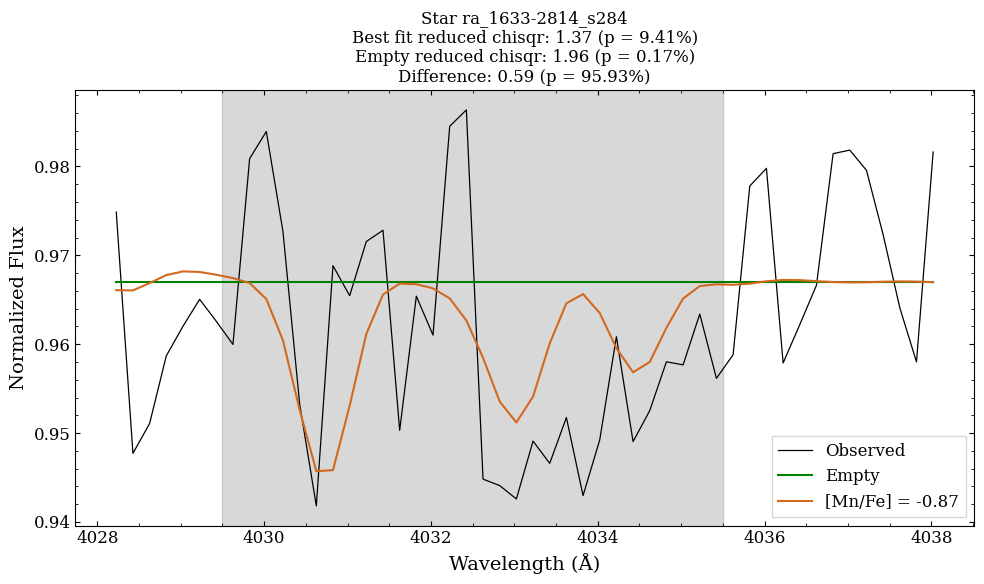

In [4]:
# Calculating the chi-squared and reduced chi-squared for the best fit and the empty spectrum
obs_fit_chisqr, obs_fit_redchisqr = reduced_chisqr(obs_flux_reg, obs_flux_err_reg, bestfit_flux_reg, 3)
obs_empty_chisqr, obs_empty_redchisqr = reduced_chisqr(obs_flux_reg, obs_flux_err_reg, empty_spec_reg, 2)

println(obs_fit_chisqr, " ", obs_empty_chisqr)
println("Reduced chi-squared for the best fit: $(round(obs_fit_redchisqr, digits=2))")
println("Reduced chi-squared for the empty spectrum: $(round(obs_empty_redchisqr, digits=2))")

# Computing the p-value for the best fit
nu_bestfit = length(bestfit_flux_reg) - 3 # degrees of freedom
p_bestfit = gammaincc(nu_bestfit/2,obs_fit_chisqr/2)
println("p-value for the best fit: $(round(p_bestfit * 100, digits=4))%")

# Computing the p-value for the empty spectra
nu_emptyfit = length(empty_spec_reg) - 2 # degrees of freedom
p_emptyfit = gammaincc(nu_emptyfit/2,obs_empty_chisqr/2)
println("p-value for the empty spectrum: $(round(p_emptyfit * 100, digits=4))%")

# Computing the difference in reduced chi-squared, then determining the p-value for the difference
diff_redchisqr = abs(obs_fit_redchisqr - obs_empty_redchisqr)
diff_chisqr = abs(obs_fit_chisqr - obs_empty_chisqr)
nu_diff = length(bestfit_flux_reg) # Same length as the best fit
p_diff = gammaincc(nu_diff/2, diff_chisqr/2)
println("p-value for the difference: $(round(p_diff * 100, digits=4))%")

# Plotting the results
line_plot_reg = 5.0 # ±5 A
wave_fit_plot_mask = (bestfit_wave .> line_cent - line_plot_reg) .& (bestfit_wave .< line_cent + line_plot_reg)
wave_obs_plot_mask = (obs_wave .> line_cent - line_plot_reg) .& (obs_wave .< line_cent + line_plot_reg)

figure(figsize=(10, 6))
title("Star ra_1633-2814_s284\nBest fit reduced chisqr: $(round(obs_fit_redchisqr, digits=2)) (p = $(round(p_bestfit * 100, digits=2))%)\nEmpty reduced chisqr: $(round(obs_empty_redchisqr, digits=2)) (p = $(round(p_emptyfit * 100, digits=2))%)\nDifference: $(abs(round(diff_redchisqr, digits=2))) (p = $(round(p_diff * 100, digits=2))%)", fontsize=12)
plot(obs_wave[wave_obs_plot_mask], obs_flux[wave_obs_plot_mask], label="Observed", color="black", linewidth=0.9)
plot(obs_wave[wave_obs_plot_mask], empty_spec[wave_obs_plot_mask], label="Empty", color="green")
plot(bestfit_wave[wave_fit_plot_mask], bestfit_flux[wave_fit_plot_mask], label="[Mn/Fe] = -0.87", color="chocolate")
axvspan(4029.5, 4035.5, color="grey", alpha=0.3)
# text(4034.7, 0.985, "Best fit reduced chisqr: $(round(obs_fit_redchisqr, digits=2))", color="black", ha="right")
# text(4034.7, 0.983, "Empty reduced chisqr: $(round(obs_empty_redchisqr, digits=2))", color="black", ha="right")
# text(4034.7, 0.981, "Dfference: $(abs(round(obs_fit_redchisqr - obs_empty_redchisqr, digits=2)))", color="black", ha="right", fontweight="bold")
# axvline(4033.06, color="grey", linestyle="--")
# text(4128.3, 0.9955, "Empty reduced chisqr: $(round(obs_empty_chisqr, digits=2))", color="black")
# text(4128.3, 0.993, "Dfference: $(abs(round(obs_fit_chisqr - obs_empty_chisqr, digits=2)))", color="black")
xlabel("Wavelength (Å)")
ylabel("Normalized Flux")
legend(fancybox=false)
tight_layout()


# savefig("/data/misfit/benlowe/results/upper_limits/ra_1633-2814_s284/ra_1633-2814_s284_Mn_I.png", dpi=300, transparent=false, facecolor="white")
display(gcf())

Using the EW minimum equation to identify what the upper-limits should be

In [5]:
function ew_min(wave_cent, sn, pixel_step, res)
    """ Calculate the minimum equivalent width (EW) for a given signal-to-noise ratio (sn), pixel step, and resolution (res).

    Parameters:
    ----------
    sn : float
        The signal-to-noise ratio of the spectra.
    pixel_step : float
        The pixel step size in the spectra.
    res : float
        The resolution of the spectra.
    
    Returns:
    -------
    min_ew : float
        The minimum observed equivalent width of the given spectra.
    """

    # Defining the parameters
    epsilon = 1/sn
    delta_x = pixel_step
    fwhm = wave_cent / res
    
    # Calculate the minimum equivalent width (in Angstroms)
    min_ew = 3 * (1.5 * sqrt(fwhm * delta_x) * epsilon)
    return min_ew
end

# Spectral quality parameters
# sn = mean(obs_flux)/std(obs_flux)
sn = 122.4875760981559 # Signal-to-noise ratio
pixel_step = mean(diff(obs_wave))
res = 5400

# Central wavelengths for the three Mn I lines
wave_cent_mn1 = 4030.75
wave_cent_mn2 = 4033.06
wave_cent_mn3 = 4034.48

# Determining the minimum equivalent width for each line
min_ew_mn1 = ew_min(wave_cent_mn1, sn, pixel_step, res)
min_ew_mn2 = ew_min(wave_cent_mn2, sn, pixel_step, res)
min_ew_mn3 = ew_min(wave_cent_mn3, sn, pixel_step, res)

all_min_ew = [min_ew_mn1, min_ew_mn2, min_ew_mn3]

println("Signal-to-noise: $(round(sn, digits=2))")
println("Minimum Equivalent Width for Mn I 4030.75 Å: $(round(min_ew_mn1, digits=4)) Å")
println("Minimum Equivalent Width for Mn I 4033.06 Å: $(round(min_ew_mn2, digits=4)) Å")
println("Minimum Equivalent Width for Mn I 4034.48 Å: $(round(min_ew_mn3, digits=4)) Å")

Signal-to-noise: 122.49
Minimum Equivalent Width for Mn I 4030.75 Å: 0.0142 Å
Minimum Equivalent Width for Mn I 4033.06 Å: 0.0142 Å
Minimum Equivalent Width for Mn I 4034.48 Å: 0.0142 Å


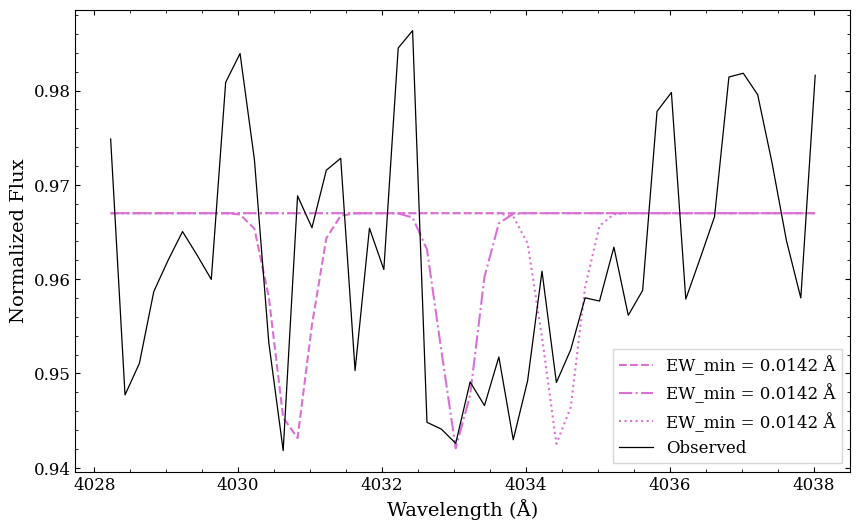

In [6]:
function gauss(waves, wave_cent, res, ew)
    """ Creates a Gaussian function rescaled to the minimum EW, with a FWHM determined by the spectral resolution.
    
    Parameters:
    ----------
    waves : Vector{Float64}
        The wavelength array for which the Gaussian is calculated.
    wave_cent : Float64
        The central wavelength of the line.
    res : Float64
        The spectral resolution of the instrument.
    ew : Float64
        The equivalent width of the line.

    Returns:
    -------
    gaussian : Vector{Float64}
        The Gaussian function values at the specified wavelengths.
    """

    # Calculate the FWHM given the spectral resolution
    fwhm = wave_cent / res

    # Calculate the standard deviation of the Gaussian using the FWHM
    sigma = fwhm / (2 * sqrt(2 * log(2) * 2))

    # Calculate the amplitude
    A = ew / (sigma * sqrt(2 * pi))

    # Create the Gaussian function
    gaussian = 0.967 .- A * exp.(-1 * (waves .- wave_cent).^2 ./ (2 * sigma^2))

    return gaussian
end

# Calculating Gaussians for each line
spec_theoretic_mn1 = gauss(obs_wave, wave_cent_mn1, res, min_ew_mn1)
spec_theoretic_mn2 = gauss(obs_wave, wave_cent_mn2, res, min_ew_mn2)
spec_theoretic_mn3 = gauss(obs_wave, wave_cent_mn3, res, min_ew_mn3)

# Plotting the theoretical spectra for each line
figure(figsize=(10, 6))
plot(obs_wave[wave_obs_plot_mask], spec_theoretic_mn1[wave_obs_plot_mask], label="EW_min = $(round(min_ew_mn1, digits=4)) Å", color="orchid", linestyle="--")
plot(obs_wave[wave_obs_plot_mask], spec_theoretic_mn2[wave_obs_plot_mask], label="EW_min = $(round(min_ew_mn2, digits=4)) Å", color="orchid", linestyle="-.")
plot(obs_wave[wave_obs_plot_mask], spec_theoretic_mn3[wave_obs_plot_mask], label="EW_min = $(round(min_ew_mn3, digits=4)) Å", color="orchid", linestyle=":")
plot(obs_wave[wave_obs_plot_mask], obs_flux[wave_obs_plot_mask], label="Observed", color="black", linewidth=0.9)
xlabel("Wavelength (Å)")
ylabel("Normalized Flux")
legend(fancybox=false)
# savefig("/data/misfit/benlowe/results/upper_limits/ra_1633-2814_s284/MnI_SN50_1xEW.png", dpi=300, transparent=false, facecolor="white")
display(gcf())

# figure(figsize=(10, 6))
# plot(obs_wave, spec_theoretic, label="Theoretical", color="black", linewidth=0.9)
# plot(obs_wave, obs_flux, label="Observed", color="darkgreen", linewidth=0.9)
# xlabel("Wavelength (Å)")
# ylabel("Normalized Flux")
# legend(fancybox=false)
# display(gcf())


In [7]:
function get_linelist(path)
    """
    Retrieves the line list from the given path, then converts to format accepted by Korg.

    Parameters
    ----------
    path : Str
        Path to the linelist.

    Returns
    -------
    linelist : Vector
        The linelist in a suitable format for Korg.
    """

    # Loading in the linelist from the given path
    linetable = CSV.read(path, DataFrame)
    linetable = sort(linetable, :wave)

    # Extracting
    linelist = Korg.Line.(Korg.air_to_vacuum.(linetable.wave),
                          linetable.loggf,
                          Korg.Species.(linetable.species),
                          linetable.elow) 

    return linelist 
end

# Loading in the stellar parameters
emp_params = CSV.read("/data/misfit/benlowe/xshooter/korg_data/abunds/final/stellar_params.csv", DataFrame)
emp_params = emp_params[emp_params.star_id .== "ra_1633-2814_s284", :]

teff = emp_params.teff[1] # in K
logg = emp_params.logg[1] # in log(cm/s^2)
feh = emp_params.Fe_it2[1] # in [Fe/H]
ah = 0.4 + feh # in [A/H]

# Loading in the linelist
linelist = get_linelist("/data/misfit/benlowe/xshooter/linelist/abund_lines/v3/Mn_I/lines_Mn_I_ALL.csv")
# linelist = get_linelist("/data/misfit/benlowe/xshooter/linelist/abund_lines/v3/Eu_II/lines_Eu_II.csv")


# Loading in the chemical abundances
emp_abunds = CSV.read("/data/misfit/benlowe/xshooter/korg_data/abunds/final/stellar_abunds.csv", DataFrame)
emp_abunds = emp_abunds[emp_abunds.star_id .== "ra_1633-2814_s284", :]

A_x = Korg.format_A_X(feh, ah, Dict("Fe" => feh, "Mg" => emp_abunds.Mg_I_xh_it2[1], "Ca" => emp_abunds.Ca_II_xh_it2[1],
"Ba" => 0 + feh, "Al" => emp_abunds.Al_I_xh_it2[1], "Mn" => emp_abunds.Mn_I_xh_it2[1], "Co" => emp_abunds.Co_I_xh_it2[1],
"Na" => emp_abunds.Na_I_xh_it2[1], "Si" => emp_abunds.Si_I_xh_it2[1], "Cr" => emp_abunds.Cr_I_xh_it2[1], "Eu" => 0 + feh,
"N" => 0 + feh, "Ni" => emp_abunds.Ni_I_xh_it2[1],
"Ti" => emp_abunds.Ti_II_xh_it2[1], "Sc" => emp_abunds.Sc_II_xh_it2[1], "Sr" => emp_abunds.Sr_II_xh_it2[1], "C" => emp_abunds.C_I_xh_it2[1]))

# # Interpolating the MARCS model atmosphere
# atm = Korg.interpolate_marcs(teff, logg, A_x)

# # Loading in the solar abundances from Asplund et al. (2021)
# solar_abunds_ax = Korg.asplund_2020_solar_abundances

# @time min_abund = Korg.Fit.ews_to_abundances(atm, linelist, A_x, all_min_ew * 1000)
# min_abund_xfe = min_abund .- solar_abunds_ax[Korg.atomic_numbers["Mn"]] .- feh
# mean_min_abund_xfe = min_abund_xfe[1]
# # min_abund_xfe = min_abund[1] - solar_abunds_ax[Korg.atomic_numbers["Mn"]] - feh

# println("Mimimum observed abundance: [Mn/Fe] = $(round(mean_min_abund_xfe, digits=2))")

92-element Vector{Float64}:
 12.0
 10.91
 -2.8255616415425284
 -2.4055616415425285
 -1.0855616415425282
  5.319062487917462
  4.044438358457471
  5.304438358457471
  0.614438358457472
  4.674438358457472
  ⋮
 -8.785561641542529
 -8.785561641542529
 -8.785561641542529
 -8.785561641542529
 -8.785561641542529
 -8.785561641542529
 -3.7555616415425286
 -8.785561641542529
 -4.325561641542528

In [8]:
Dict("Fe" => feh, "Mg" => emp_abunds.Mg_I_xh_it2[1], "Ca" => emp_abunds.Ca_II_xh_it2[1],
"Ba" => 0 + feh, "Al" => emp_abunds.Al_I_xh_it2[1], "Mn" => emp_abunds.Mn_I_xh_it2[1], "Co" => emp_abunds.Co_I_xh_it2[1],
"Na" => emp_abunds.Na_I_xh_it2[1], "Si" => emp_abunds.Si_I_xh_it2[1], "Cr" => emp_abunds.Cr_I_xh_it2[1], "Eu" => 0 + feh,
"N" => 0 + feh, "Ni" => emp_abunds.Ni_I_xh_it2[1],
"Ti" => emp_abunds.Ti_II_xh_it2[1], "Sc" => emp_abunds.Sc_II_xh_it2[1], "Sr" => emp_abunds.Sr_II_xh_it2[1], "C" => emp_abunds.C_I_xh_it2[1])

Dict{String, Float64} with 17 entries:
  "Na" => -3.71273
  "Cr" => -4.05742
  "Si" => -3.25769
  "Ni" => -3.98755
  "C"  => -3.14094
  "Co" => -2.93661
  "Ba" => -3.78556
  "Al" => -4.58969
  "Ti" => -3.44291
  "Mn" => -4.65658
  "N"  => -3.78556
  "Fe" => -3.78556
  "Ca" => -3.26872
  "Sc" => -3.72617
  "Mg" => -3.38377
  "Eu" => -3.78556
  "Sr" => -3.33117

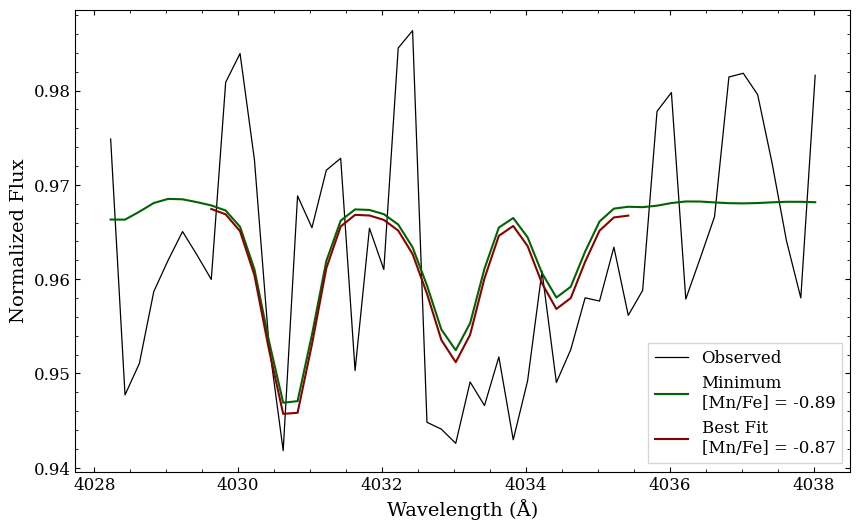

In [10]:
min_spec = CSV.read("/data/misfit/benlowe/xshooter/korg_data/synths/ra_1633-2814_s284/Mn_I/obs/line_4033.06/spectra/-0.89_spec.csv", DataFrame)
min_wave = ast.literal_eval.(min_spec.fit_wave[1])
min_flux = ast.literal_eval.(min_spec.fit_flux[1])
min_flux_err = ast.literal_eval.(min_spec.obs_flux_err[1])



figure(figsize=(10, 6))
plot(obs_wave[wave_obs_plot_mask], obs_flux[wave_obs_plot_mask], label="Observed", color="black", linewidth=0.9)
plot(min_wave[wave_obs_plot_mask], min_flux[wave_obs_plot_mask], label="Minimum\n[Mn/Fe] = $(round(mean_min_abund_xfe, digits=2))", color="darkgreen")
plot(bestfit_wave_reg, bestfit_flux_reg, label="Best Fit\n[Mn/Fe] = -0.87", color="darkred")
xlabel("Wavelength (Å)")
ylabel("Normalized Flux")

legend(fancybox=false)

savefig("/data/misfit/benlowe/results/upper_limits/ra_1633-2814_s284/Mn_I_min_spec.png", dpi=300, transparent=false, facecolor="white")
display(gcf())

#### For Eu

In [1]:
# Loading in the best fit spectrum
bestfit_path = "//data/misfit/benlowe/xshooter/korg_data/abunds/final/ra_1633-2814_s284/Eu_II/iter_2/fits_data/Eu_4129.725_fit.csv"

bestfit_df = CSV.read(bestfit_path, DataFrame)

bestfit_wave = bestfit_df.wave
bestfit_flux = bestfit_df.best_fit

# Loading in the observed spectrum
obs_path = "/data/misfit/benlowe/xshooter/korg_data/synths/ra_1633-2814_s284/Eu_II/obs/line_4129.725/spectra/0.44_spec.csv"

obs_df = CSV.read(obs_path, DataFrame)
obs_wave = ast.literal_eval.(obs_df.obs_wave[1])
obs_flux = ast.literal_eval.(obs_df.obs_flux[1])
obs_flux_err = ast.literal_eval.(obs_df.obs_flux_err[1])

# Creating the empty spectrum
empty_spec = repeat([0.9717], length(obs_wave))
# poly_coeffs = np.polyfit(wave_fit, flux_obs, 1)
# poly_fit = poly_coeffs[1]*wave_obs .+ poly_coeffs[2]

# Slicing the region of interest
line_cent = 4129.725
line_chisqr_reg = 1.5 # ±1 A
wave_fit_mask = (bestfit_wave .> line_cent - line_chisqr_reg) .& (bestfit_wave .< line_cent + line_chisqr_reg)
wave_obs_mask = (obs_wave .> line_cent - line_chisqr_reg) .& (obs_wave .< line_cent + line_chisqr_reg)

bestfit_wave_reg = bestfit_wave[wave_fit_mask]
bestfit_flux_reg = bestfit_flux[wave_fit_mask]
obs_wave_reg = obs_wave[wave_obs_mask]
obs_flux_reg = obs_flux[wave_obs_mask]
obs_flux_err_reg = obs_flux_err[wave_obs_mask]
empty_spec_reg = empty_spec[wave_obs_mask]

UndefVarError: UndefVarError: `CSV` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

28.003764265983023 31.597718167818407
Reduced chi-squared for the best fit: 2.33
Reduced chi-squared for the empty spectrum: 2.43
p-value for the best fit: 0.5525%
p-value for the empty spectrum: 0.2755%
p-value for the difference: 99.8793%


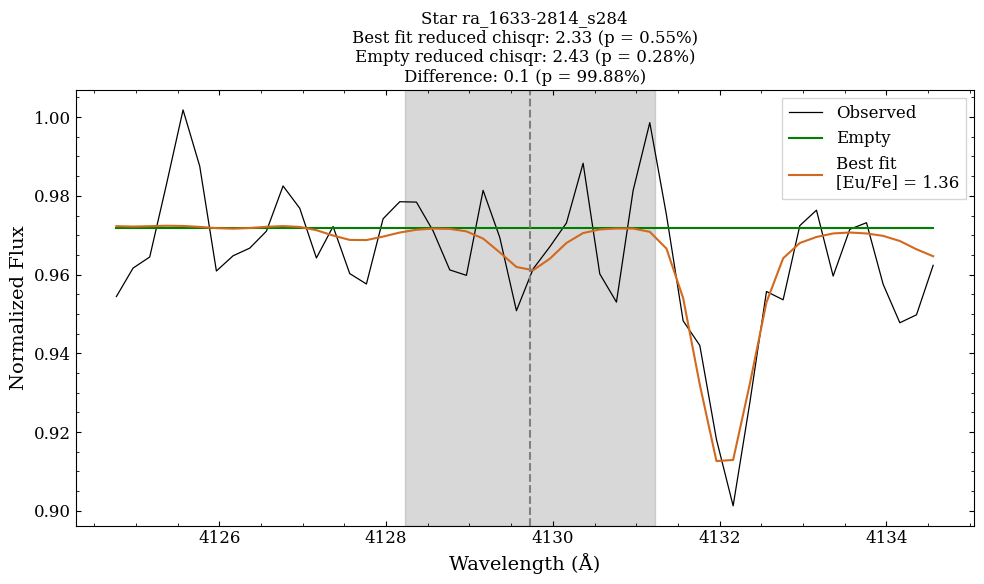

In [9]:
obs_fit_chisqr, obs_fit_redchisqr = reduced_chisqr(obs_flux_reg, obs_flux_err_reg, bestfit_flux_reg, 3)
obs_empty_chisqr, obs_empty_redchisqr = reduced_chisqr(obs_flux_reg, obs_flux_err_reg, empty_spec_reg, 2)

println(obs_fit_chisqr, " ", obs_empty_chisqr)
println("Reduced chi-squared for the best fit: $(round(obs_fit_redchisqr, digits=2))")
println("Reduced chi-squared for the empty spectrum: $(round(obs_empty_redchisqr, digits=2))")

# Computing the p-value for the best fit
nu = length(bestfit_flux_reg) - 3 # degrees of freedom
p_bestfit = gammaincc(nu/2,obs_fit_chisqr/2)
println("p-value for the best fit: $(round(p_bestfit * 100, digits=4))%")

# Computing the p-value for the empty spectra
nu = length(empty_spec_reg) - 2 # degrees of freedom
p_emptyfit = gammaincc(nu/2,obs_empty_chisqr/2)
println("p-value for the empty spectrum: $(round(p_emptyfit * 100, digits=4))%")

# Computing the difference in reduced chi-squared, then determining the p-value for the difference
diff_redchisqr = abs(obs_fit_redchisqr - obs_empty_redchisqr)
diff_chisqr = abs(obs_fit_chisqr - obs_empty_chisqr)
nu_diff = length(bestfit_flux_reg) # Same length as the best fit
p_diff = gammaincc(nu_diff/2, diff_chisqr/2)
println("p-value for the difference: $(round(p_diff * 100, digits=4))%")

# Plotting the results
line_plot_reg = 5.0 # ±5 A
wave_fit_plot_mask = (bestfit_wave .> line_cent - line_plot_reg) .& (bestfit_wave .< line_cent + line_plot_reg)
wave_obs_plot_mask = (obs_wave .> line_cent - line_plot_reg) .& (obs_wave .< line_cent + line_plot_reg)

figure(figsize=(10, 6))
title("Star ra_1633-2814_s284\nBest fit reduced chisqr: $(round(obs_fit_redchisqr, digits=2)) (p = $(round(p_bestfit * 100, digits=2))%)\nEmpty reduced chisqr: $(round(obs_empty_redchisqr, digits=2)) (p = $(round(p_emptyfit * 100, digits=2))%)\nDifference: $(abs(round(diff_redchisqr, digits=2))) (p = $(round(p_diff * 100, digits=2))%)", fontsize=12)
plot(obs_wave[wave_obs_plot_mask], obs_flux[wave_obs_plot_mask], label="Observed", color="black", linewidth=0.9)
plot(obs_wave[wave_obs_plot_mask], empty_spec[wave_obs_plot_mask], label="Empty", color="green")
plot(bestfit_wave[wave_fit_plot_mask], bestfit_flux[wave_fit_plot_mask], label="Best fit\n[Eu/Fe] = 1.36", color="chocolate")
axvspan(line_cent - line_chisqr_reg, line_cent + line_chisqr_reg, color="grey", alpha=0.3)
# text(4128.2, 0.998, "Best fit reduced chisqr: $(round(obs_fit_redchisqr, digits=2))", color="black")
# text(4128.2, 0.9955, "Empty reduced chisqr: $(round(obs_empty_redchisqr, digits=2))", color="black")
# text(4128.2, 0.993, "Dfference: $(abs(round(obs_fit_redchisqr - obs_empty_redchisqr, digits=2)))", color="black", fontweight="bold")
axvline(4129.725, color="grey", linestyle="--")
xlabel("Wavelength (Å)")
ylabel("Normalized Flux")
legend(fancybox=false)
tight_layout()


# savefig("/data/misfit/benlowe/results/upper_limits/ra_1633-2814_s284/ra_1633-2814_s284_Eu_II.png", dpi=300, transparent=false, facecolor="white")
display(gcf())

Using the EW minimum equation to identify what the upper-limits should be

In [10]:
function ew_min(wave_cent, sn, pixel_step, res)
    """ Calculate the minimum equivalent width (EW) for a given signal-to-noise ratio (sn), pixel step, and resolution (res).

    Parameters:
    ----------
    sn : float
        The signal-to-noise ratio of the spectra.
    pixel_step : float
        The pixel step size in the spectra.
    res : float
        The resolution of the spectra.
    
    Returns:
    -------
    min_ew : float
        The minimum observed equivalent width of the given spectra.
    """

    # Defining the parameters
    epsilon = 1/sn
    delta_x = pixel_step
    fwhm = wave_cent / res
    
    # Calculate the minimum equivalent width (in Angstroms)
    min_ew = 3 * (1.5 * sqrt(fwhm * delta_x) * epsilon)
    return min_ew
end

# Spectral quality parameters
# sn = 122.4875760981559
mean(obs_flux)/std(obs_flux)
pixel_step = mean(diff(obs_wave))
res = 5400

# Central wavelengths for the three Mn I lines
wave_cent_eu1 = 4129.725

# Determining the minimum equivalent width for each line
min_ew_eu1 = ew_min(wave_cent_mn1, sn, pixel_step, res)

all_min_ew = [min_ew_eu1]

println("Signal-to-noise: $(round(sn, digits=2))")
println("Minimum Equivalent Width for Eu I 4129.725 Å: $(round(min_ew_eu1, digits=4)) Å")

Signal-to-noise: 49.98
Minimum Equivalent Width for Eu I 4129.725 Å: 0.0348 Å


0.7647638888888889
0.2296437610937788
0.06041649841225924


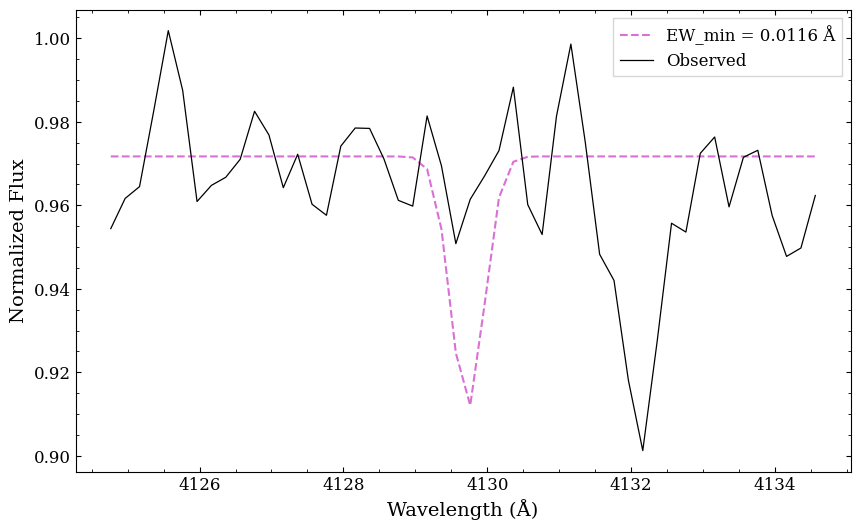

In [11]:
function gauss(waves, wave_cent, res, ew)
    """ Creates a Gaussian function rescaled to the minimum EW, with a FWHM determined by the spectral resolution.
    
    Parameters:
    ----------
    waves : Vector{Float64}
        The wavelength array for which the Gaussian is calculated.
    wave_cent : Float64
        The central wavelength of the line.
    res : Float64
        The spectral resolution of the instrument.
    ew : Float64
        The equivalent width of the line.

    Returns:
    -------
    gaussian : Vector{Float64}
        The Gaussian function values at the specified wavelengths.
    """

    # Calculate the FWHM given the spectral resolution
    fwhm = wave_cent / res
    println(fwhm)

    # Calculate the standard deviation of the Gaussian using the FWHM
    sigma = fwhm / (2 * sqrt(2 * log(2) * 2))
    println(sigma)

    # Calculate the amplitude
    A = ew / (sigma * sqrt(2 * pi))
    println(A)

    # Create the Gaussian function
    gaussian = 0.9717 .- A * exp.(-1 * (waves .- wave_cent).^2 ./ (2 * sigma^2))

    return gaussian
end

# Calculating Gaussians for each line
spec_theoretic_eu1 = gauss(obs_wave, wave_cent_eu1, res, min_ew_eu1)

# Plotting the theoretical spectra for each line
figure(figsize=(10, 6))
plot(obs_wave[wave_obs_plot_mask], spec_theoretic_eu1[wave_obs_plot_mask], label="EW_min = $(round(min_ew_mn1, digits=4)) Å", color="orchid", linestyle="--")
plot(obs_wave[wave_obs_plot_mask], obs_flux[wave_obs_plot_mask], label="Observed", color="black", linewidth=0.9)
xlabel("Wavelength (Å)")
ylabel("Normalized Flux")
legend(fancybox=false)
# savefig("/data/misfit/benlowe/results/upper_limits/ra_1633-2814_s284/Eu_I_theoretical_spec.png", dpi=300, transparent=false, facecolor="white")
display(gcf())

# figure(figsize=(10, 6))
# plot(obs_wave, spec_theoretic, label="Theoretical", color="black", linewidth=0.9)
# plot(obs_wave, obs_flux, label="Observed", color="darkgreen", linewidth=0.9)
# xlabel("Wavelength (Å)")
# ylabel("Normalized Flux")
# legend(fancybox=false)
# display(gcf())


In [79]:
function get_linelist(path)
    """
    Retrieves the line list from the given path, then converts to format accepted by Korg.

    Parameters
    ----------
    path : Str
        Path to the linelist.

    Returns
    -------
    linelist : Vector
        The linelist in a suitable format for Korg.
    """

    # Loading in the linelist from the given path
    linetable = CSV.read(path, DataFrame)
    linetable = sort(linetable, :wave)

    # Extracting
    linelist = Korg.Line.(Korg.air_to_vacuum.(linetable.wave),
                          linetable.loggf,
                          Korg.Species.(linetable.species),
                          linetable.elow) 

    return linelist 
end

# Loading in the stellar parameters
emp_params = CSV.read("/data/misfit/benlowe/xshooter/korg_data/abunds/final/stellar_params.csv", DataFrame)
emp_params = emp_params[emp_params.star_id .== "ra_1633-2814_s284", :]

teff = emp_params.teff[1] # in K
logg = emp_params.logg[1] # in log(cm/s^2)
feh = emp_params.Fe_it2[1] # in [Fe/H]
ah = 0.4 + feh # in [A/H]

# Loading in the linelist
# linelist = get_linelist("/data/misfit/benlowe/xshooter/linelist/abund_lines/v3/Mn_I/lines_Mn_I_ALL.csv")
linelist = get_linelist("/data/misfit/benlowe/xshooter/linelist/abund_lines/v3/Eu_II/lines_Eu_II.csv")


# Loading in the chemical abundances
emp_abunds = CSV.read("/data/misfit/benlowe/xshooter/korg_data/abunds/final/stellar_abunds.csv", DataFrame)
emp_abunds = emp_abunds[emp_abunds.star_id .== "ra_1633-2814_s284", :]

A_x = Korg.format_A_X(feh, ah, Dict("Fe" => feh, "Mg" => emp_abunds.Mg_I_xh_it2[1], "Ca" => emp_abunds.Ca_II_xh_it2[1],
"Ba" => 0 + feh, "Al" => emp_abunds.Al_I_xh_it2[1], "Mn" => emp_abunds.Mn_I_xh_it2[1], "Co" => emp_abunds.Co_I_xh_it2[1],
"Na" => emp_abunds.Na_I_xh_it2[1], "Si" => emp_abunds.Si_I_xh_it2[1], "Cr" => emp_abunds.Cr_I_xh_it2[1], "Eu" => 0 + feh,
"N" => 0 + feh, "Ni" => emp_abunds.Ni_I_xh_it2[1],
"Ti" => emp_abunds.Ti_II_xh_it2[1], "Sc" => emp_abunds.Sc_II_xh_it2[1], "Sr" => emp_abunds.Sr_II_xh_it2[1], "C" => emp_abunds.C_I_xh_it2[1]))

# Interpolating the MARCS model atmosphere
atm = Korg.interpolate_marcs(teff, logg, A_x)

# Loading in the solar abundances from Asplund et al. (2021)
solar_abunds_ax = Korg.asplund_2020_solar_abundances

@time min_abund = Korg.Fit.ews_to_abundances(atm, linelist, A_x, all_min_ew * 1000)
min_abund_xfe = mean(min_abund .- solar_abunds_ax[Korg.atomic_numbers["Eu"]] .- feh)
# min_abund_xfe = min_abund[1] - solar_abunds_ax[Korg.atomic_numbers["Mn"]] - feh

println("Mimimum observed abundance: [Eu/Fe] = $(round(min_abund_xfe, digits=2))")

  0.527991 seconds (2.39 M allocations: 181.164 MiB, 4.68% gc time)
Mimimum observed abundance: [Eu/Fe] = 1.66


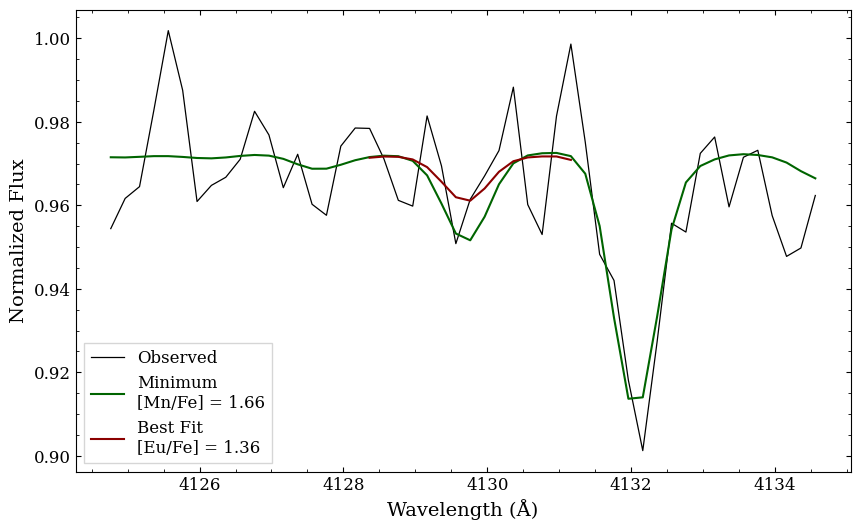

In [82]:
min_spec = CSV.read("/data/misfit/benlowe/xshooter/korg_data/synths/ra_1633-2814_s284/Eu_II/obs/line_4129.725/spectra/1.66_spec.csv", DataFrame)
min_wave = ast.literal_eval.(min_spec.fit_wave[1])
min_flux = ast.literal_eval.(min_spec.fit_flux[1])
min_flux_err = ast.literal_eval.(min_spec.obs_flux_err[1])



figure(figsize=(10, 6))
plot(obs_wave[wave_obs_plot_mask], obs_flux[wave_obs_plot_mask], label="Observed", color="black", linewidth=0.9)
plot(min_wave[wave_obs_plot_mask], min_flux[wave_obs_plot_mask], label="Minimum\n[Mn/Fe] = $(round(min_abund_xfe, digits=2))", color="darkgreen")
plot(bestfit_wave_reg, bestfit_flux_reg, label="Best Fit\n[Eu/Fe] = 1.36", color="darkred")
xlabel("Wavelength (Å)")
ylabel("Normalized Flux")

legend(fancybox=false)

savefig("/data/misfit/benlowe/results/upper_limits/ra_1633-2814_s284/Eu_I_min_spec.png", dpi=300, transparent=false, facecolor="white")
display(gcf())

#### For Mg

In [12]:
# Loading in the best fit spectrum
bestfit_path = "/data/misfit/benlowe/xshooter/korg_data/abunds/final/ra_1633-2814_s284/Mg_I/iter_2/fits_data/Mg_5167.322_fit.csv"

bestfit_df = CSV.read(bestfit_path, DataFrame)

bestfit_wave = bestfit_df.wave
bestfit_flux = bestfit_df.best_fit

# Loading in the observed spectrum
obs_path = "/data/misfit/benlowe/xshooter/korg_data/synths/test/test1_currentwindows/ra_1633-2814_s284/Mg_I/obs/line_5167.322/spectra/-0.0_spec.csv"

obs_df = CSV.read(obs_path, DataFrame)
obs_wave = ast.literal_eval.(obs_df.obs_wave[1])
obs_flux = ast.literal_eval.(obs_df.obs_flux[1])
obs_flux_err = ast.literal_eval.(obs_df.obs_flux_err[1])

# Creating the empty spectrum
empty_spec = repeat([0.974], length(obs_wave))

# figure(figsize=(10, 6))
# plot(obs_wave, obs_flux, label="Observed", color="black", linewidth=0.9)
# plot(bestfit_wave, bestfit_flux, label="[Mg/Fe] = -0.09", color="darkorange")
# plot(obs_wave, empty_spec, label="Empty", color="green")
# display(gcf())

# Slicing the region of interest
wave_fit_mask = (bestfit_wave .> 5165.5) .& (bestfit_wave .< 5174.5)
wave_obs_mask = (obs_wave .> 5165.5) .& (obs_wave .< 5174.5)

bestfit_wave_reg = bestfit_wave[wave_fit_mask]
bestfit_flux_reg = bestfit_flux[wave_fit_mask]
obs_wave_reg = obs_wave[wave_obs_mask]
obs_flux_reg = obs_flux[wave_obs_mask]
obs_flux_err_reg = obs_flux_err[wave_obs_mask]
empty_spec_reg = empty_spec[wave_obs_mask]

46-element Vector{Float64}:
 0.974
 0.974
 0.974
 0.974
 0.974
 0.974
 0.974
 0.974
 0.974
 0.974
 ⋮
 0.974
 0.974
 0.974
 0.974
 0.974
 0.974
 0.974
 0.974
 0.974

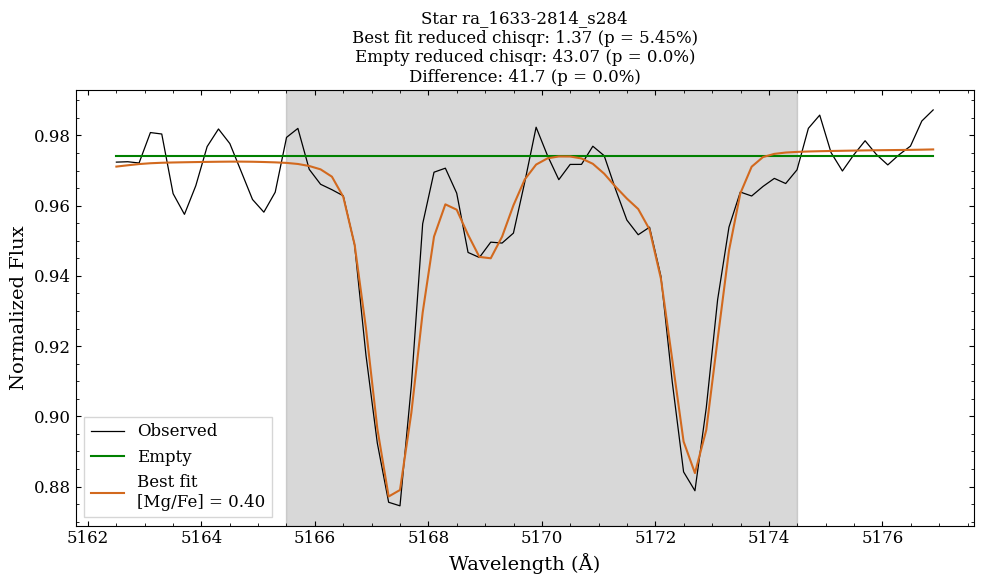

58.82529943985838 1895.142465068914
Reduced chi-squared for the best fit: 1.37
Reduced chi-squared for the empty spectrum: 43.07
p-value for the best fit: 5.4461%
p-value for the empty spectrum: 0.0%
p-value for the difference: 0.0%


In [13]:
obs_fit_chisqr, obs_fit_redchisqr = reduced_chisqr(obs_flux_reg, obs_flux_err_reg, bestfit_flux_reg, 3)
obs_empty_chisqr, obs_empty_redchisqr = reduced_chisqr(obs_flux_reg, obs_flux_err_reg, empty_spec_reg, 2)

println(obs_fit_chisqr, " ", obs_empty_chisqr)
println("Reduced chi-squared for the best fit: $(round(obs_fit_redchisqr, digits=2))")
println("Reduced chi-squared for the empty spectrum: $(round(obs_empty_redchisqr, digits=2))")

# Computing the p-value for the best fit
nu = length(bestfit_flux_reg) - 3 # degrees of freedom
p_bestfit = gammaincc(nu/2,obs_fit_chisqr/2)
println("p-value for the best fit: $(round(p_bestfit * 100, digits=4))%")

# Computing the p-value for the empty spectra
nu = length(empty_spec_reg) - 2 # degrees of freedom
p_emptyfit = gammaincc(nu/2,obs_empty_chisqr/2)
println("p-value for the empty spectrum: $(round(p_emptyfit * 100, digits=4))%")

# Computing the difference in reduced chi-squared, then determining the p-value for the difference
diff_redchisqr = abs(obs_fit_redchisqr - obs_empty_redchisqr)
diff_chisqr = abs(obs_fit_chisqr - obs_empty_chisqr)
nu_diff = length(bestfit_flux_reg) # Same length as the best fit
p_diff = gammaincc(nu_diff/2, diff_chisqr/2)
println("p-value for the difference: $(round(p_diff * 100, digits=4))%")

# Plotting the results
line_plot_reg = 5.0 # ±5 A
wave_fit_plot_mask = (bestfit_wave .> 5162) .& (bestfit_wave .< 5177)
wave_obs_plot_mask = (obs_wave .> 5162) .& (obs_wave .< 5177)

figure(figsize=(10, 6))
title("Star ra_1633-2814_s284\nBest fit reduced chisqr: $(round(obs_fit_redchisqr, digits=2)) (p = $(round(p_bestfit * 100, digits=2))%)\nEmpty reduced chisqr: $(round(obs_empty_redchisqr, digits=2)) (p = $(round(p_emptyfit * 100, digits=2))%)\nDifference: $(abs(round(diff_redchisqr, digits=2))) (p = $(round(p_diff * 100, digits=2))%)", fontsize=12)
plot(obs_wave[wave_obs_plot_mask], obs_flux[wave_obs_plot_mask], label="Observed", color="black", linewidth=0.9)
plot(obs_wave[wave_obs_plot_mask], empty_spec[wave_obs_plot_mask], label="Empty", color="green")
plot(bestfit_wave[wave_fit_plot_mask], bestfit_flux[wave_fit_plot_mask], label="Best fit\n[Mg/Fe] = 0.40", color="chocolate")
axvspan(5165.5, 5174.5, color="grey", alpha=0.3)
# text(4128.2, 0.998, "Best fit reduced chisqr: $(round(obs_fit_redchisqr, digits=2))", color="black")
# text(4128.2, 0.9955, "Empty reduced chisqr: $(round(obs_empty_redchisqr, digits=2))", color="black")
# text(4128.2, 0.993, "Dfference: $(abs(round(obs_fit_redchisqr - obs_empty_redchisqr, digits=2)))", color="black", fontweight="bold")
# axvline(4129.725, color="grey", linestyle="--")
xlabel("Wavelength (Å)")
ylabel("Normalized Flux")
legend(fancybox=false)
tight_layout()

# savefig("/data/misfit/benlowe/results/upper_limits/ra_1633-2814_s284/ra_1633-2814_s284_Mg_I.png", dpi=300, transparent=false, facecolor="white")
display(gcf())

Using the EW minimum equation to identify what the upper-limits should be

In [14]:
function ew_min(wave_cent, sn, pixel_step, res)
    """ Calculate the minimum equivalent width (EW) for a given signal-to-noise ratio (sn), pixel step, and resolution (res).

    Parameters:
    ----------
    sn : float
        The signal-to-noise ratio of the spectra.
    pixel_step : float
        The pixel step size in the spectra.
    res : float
        The resolution of the spectra.
    
    Returns:
    -------
    min_ew : float
        The minimum observed equivalent width of the given spectra.
    """

    # Defining the parameters
    epsilon = 1/sn
    delta_x = pixel_step
    fwhm = wave_cent / res
    
    # Calculate the minimum equivalent width (in Angstroms)
    min_ew = 3 * (1.5 * sqrt(fwhm * delta_x) * epsilon)
    return min_ew
end

# Spectral quality parameters
# sn = 122.4875760981559
sn = mean(obs_flux)/std(obs_flux)
pixel_step = mean(diff(obs_wave))
res = 5400

# Central wavelengths for the three Mn I lines
wave_cent_mg1 = 5167.322
wave_cent_mg2 = 5172.684

# Determining the minimum equivalent width for each line
min_ew_mg1 = ew_min(wave_cent_mg1, sn, pixel_step, res)
min_ew_mg2 = ew_min(wave_cent_mg2, sn, pixel_step, res)

all_min_ew = [min_ew_mg1, min_ew_mg2]

println("Signal-to-noise: $(round(sn, digits=2))")
println("Minimum Equivalent Width for Mg I 5167.322 Å: $(round(min_ew_mg1, digits=4)) Å")
println("Minimum Equivalent Width for Mg I 5172.684 Å: $(round(min_ew_mg2, digits=4)) Å")

Signal-to-noise: 35.66
Minimum Equivalent Width for Mg I 5167.322 Å: 0.0552 Å
Minimum Equivalent Width for Mg I 5172.684 Å: 0.0552 Å


0.9569114814814815
0.28734195590811185
0.022307132494569632
0.9579044444444444
0.2876401234245893
0.022295567719141835


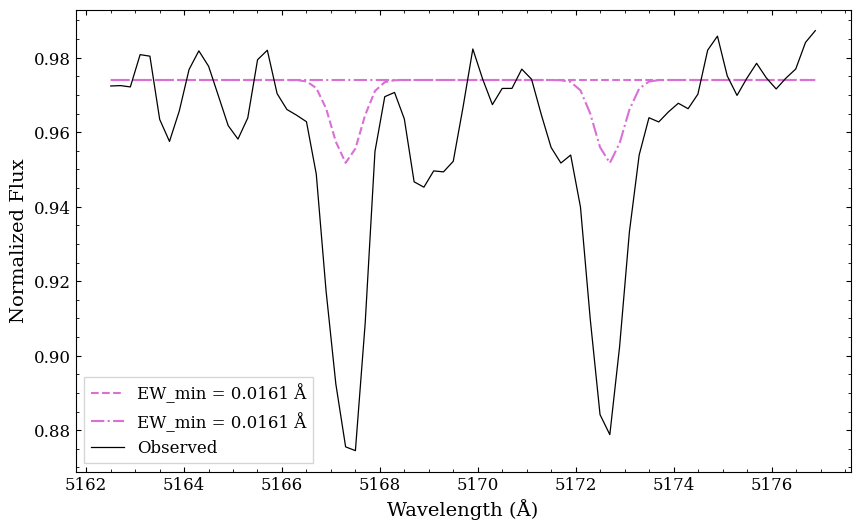

In [15]:
function gauss(waves, wave_cent, res, ew)
    """ Creates a Gaussian function rescaled to the minimum EW, with a FWHM determined by the spectral resolution.
    
    Parameters:
    ----------
    waves : Vector{Float64}
        The wavelength array for which the Gaussian is calculated.
    wave_cent : Float64
        The central wavelength of the line.
    res : Float64
        The spectral resolution of the instrument.
    ew : Float64
        The equivalent width of the line.

    Returns:
    -------
    gaussian : Vector{Float64}
        The Gaussian function values at the specified wavelengths.
    """

    # Calculate the FWHM given the spectral resolution
    fwhm = wave_cent / res
    println(fwhm)

    # Calculate the standard deviation of the Gaussian using the FWHM
    sigma = fwhm / (2 * sqrt(2 * log(2) * 2))
    println(sigma)

    # Calculate the amplitude
    A = ew / (sigma * sqrt(2 * pi))
    println(A)

    # Create the Gaussian function
    gaussian = 0.974 .- A * exp.(-1 * (waves .- wave_cent).^2 ./ (2 * sigma^2))

    return gaussian
end

# Calculating Gaussians for each line
spec_theoretic_mg1 = gauss(obs_wave, wave_cent_mg1, res, min_ew_mg1)
spec_theoretic_mg2 = gauss(obs_wave, wave_cent_mg2, res, min_ew_mg2)

# Plotting the theoretical spectra for each line
figure(figsize=(10, 6))
plot(obs_wave[wave_obs_plot_mask], spec_theoretic_mg1[wave_obs_plot_mask], label="EW_min = $(round(min_ew_mg1, digits=4)) Å", color="orchid", linestyle="--")
plot(obs_wave[wave_obs_plot_mask], spec_theoretic_mg2[wave_obs_plot_mask], label="EW_min = $(round(min_ew_mg2, digits=4)) Å", color="orchid", linestyle="-.")
plot(obs_wave[wave_obs_plot_mask], obs_flux[wave_obs_plot_mask], label="Observed", color="black", linewidth=0.9)
xlabel("Wavelength (Å)")
ylabel("Normalized Flux")
legend(fancybox=false)
savefig("/data/misfit/benlowe/results/upper_limits/ra_1633-2814_s284/Mg_I_theoretical_spec.png", dpi=300, transparent=false, facecolor="white")
display(gcf())

# figure(figsize=(10, 6))
# plot(obs_wave, spec_theoretic, label="Theoretical", color="black", linewidth=0.9)
# plot(obs_wave, obs_flux, label="Observed", color="darkgreen", linewidth=0.9)
# xlabel("Wavelength (Å)")
# ylabel("Normalized Flux")
# legend(fancybox=false)
# display(gcf())


In [129]:
function get_linelist(path)
    """
    Retrieves the line list from the given path, then converts to format accepted by Korg.

    Parameters
    ----------
    path : Str
        Path to the linelist.

    Returns
    -------
    linelist : Vector
        The linelist in a suitable format for Korg.
    """

    # Loading in the linelist from the given path
    linetable = CSV.read(path, DataFrame)
    linetable = sort(linetable, :wave)

    # Extracting
    linelist = Korg.Line.(Korg.air_to_vacuum.(linetable.wave),
                          linetable.loggf,
                          Korg.Species.(linetable.species),
                          linetable.elow) 

    return linelist 
end

# Loading in the stellar parameters
emp_params = CSV.read("/data/misfit/benlowe/xshooter/korg_data/abunds/final/stellar_params.csv", DataFrame)
emp_params = emp_params[emp_params.star_id .== "ra_1633-2814_s284", :]

teff = emp_params.teff[1] # in K
logg = emp_params.logg[1] # in log(cm/s^2)
feh = emp_params.Fe_it2[1] # in [Fe/H]
ah = 0.4 + feh # in [A/H]

# Loading in the linelist
linelist = get_linelist("/data/misfit/benlowe/xshooter/linelist/abund_lines/v3/Mg_I/lines_Mg_I.csv")
# linelist = get_linelist("/data/misfit/benlowe/xshooter/linelist/abund_lines/v3/Eu_II/lines_Eu_II.csv")


# Loading in the chemical abundances
emp_abunds = CSV.read("/data/misfit/benlowe/xshooter/korg_data/abunds/final/stellar_abunds.csv", DataFrame)
emp_abunds = emp_abunds[emp_abunds.star_id .== "ra_1633-2814_s284", :]

A_x = Korg.format_A_X(feh, ah, Dict("Fe" => feh, "Mg" => emp_abunds.Mg_I_xh_it2[1], "Ca" => emp_abunds.Ca_II_xh_it2[1],
"Ba" => 0 + feh, "Al" => emp_abunds.Al_I_xh_it2[1], "Mn" => emp_abunds.Mn_I_xh_it2[1], "Co" => emp_abunds.Co_I_xh_it2[1],
"Na" => emp_abunds.Na_I_xh_it2[1], "Si" => emp_abunds.Si_I_xh_it2[1], "Cr" => emp_abunds.Cr_I_xh_it2[1], "Eu" => 0 + feh,
"N" => 0 + feh, "Ni" => emp_abunds.Ni_I_xh_it2[1],
"Ti" => emp_abunds.Ti_II_xh_it2[1], "Sc" => emp_abunds.Sc_II_xh_it2[1], "Sr" => emp_abunds.Sr_II_xh_it2[1], "C" => emp_abunds.C_I_xh_it2[1]))

# Interpolating the MARCS model atmosphere
atm = Korg.interpolate_marcs(teff, logg, A_x)

# Loading in the solar abundances from Asplund et al. (2021)
solar_abunds_ax = Korg.asplund_2020_solar_abundances

@time min_abund = Korg.Fit.ews_to_abundances(atm, linelist, A_x, all_min_ew * 1000)
min_abund_xfe = min_abund .- solar_abunds_ax[Korg.atomic_numbers["Mg"]] .- feh
mean_min_abund_xfe = mean(min_abund_xfe)
# min_abund_xfe = min_abund[1] - solar_abunds_ax[Korg.atomic_numbers["Mn"]] - feh

println("Mimimum observed abundance: [Mg/Fe] = $(round(mean_min_abund_xfe, digits=2))")

  1.165034 seconds (5.21 M allocations: 388.177 MiB, 4.47% gc time)
Mimimum observed abundance: [Mg/Fe] = NaN


In [132]:
all_min_ew

2-element Vector{Float64}:
 0.01606692345379198
 0.016075257413433623